# Notebook 02 — Machine Learning Não Supervisionado

## Perfis de denúncias relacionadas ao tráfico de pessoas no Disque 100

Este notebook constrói a unidade analítica no nível da denúncia, preserva todas as violações concomitantes nas denúncias que contêm tráfico de pessoas e compara representações hierárquicas para agrupamento não supervisionado.

### Fluxo metodológico

1. carregar os dados preparados no Notebook 01;
2. identificar denúncias com pelo menos uma ocorrência de tráfico;
3. recuperar todas as ocorrências dessas denúncias;
4. construir matrizes binárias denúncia × classe, subclasse e espécie;
5. avaliar suporte, prevalência, variância e esparsidade;
6. comparar representações;
7. aplicar modelos de referência e modelos principais;
8. avaliar estabilidade, separação e interpretabilidade;
9. caracterizar os clusters pelas espécies e demais atributos.

> **Importante:** os algoritmos não recebem o termo usado para selecionar o subconjunto como uma variável de segmentação quando esse termo é constante ou quase constante entre todas as denúncias.


## 1. Configuração e reprodutibilidade


In [105]:
import importlib.util
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from scipy import sparse
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score,
    pairwise_distances,
)
from sklearn.preprocessing import normalize

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_colwidth", 120)

COL_DENUNCIA = "hash"
COL_VIOLACAO = "violacao"
COL_CLASSE = "violacao_classe"
COL_SUBCLASSE = "violacao_subclasse"
COL_ESPECIE = "violacao_especie"
COL_ABRANGENCIA = "violacao_abrangencia"

TERMO_TRAFICO = r"TRÁFICO|TRAFICO"
SUPORTE_MINIMO = 0.01
SUPORTE_MAXIMO = 0.99
MIN_OCORRENCIAS = 5

print("Versões")
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("umap disponível:", importlib.util.find_spec("umap") is not None)
print("hdbscan disponível:", importlib.util.find_spec("hdbscan") is not None)

Versões
pandas: 3.1.1
numpy: 2.5.4
umap disponível: False
hdbscan disponível: False


## 2. Carregamento dos dados preparados

A célula aceita duas formas de continuidade:

- `df_norm` já existente na sessão após a execução do Notebook 01; ou
- arquivo Parquet exportado pelo Notebook 01.

Ajuste `CAMINHO_DADOS` somente se necessário.


In [106]:
CAMINHO_DADOS = Path(r"C:\Projetos\eda-disque100-completo\eda\outputs\step_03_data_cleaning\disque100_clean.parquet")

if "df_norm" in globals():
    dados = df_norm.copy()
    origem_dados = "DataFrame df_norm em memória"
elif CAMINHO_DADOS.exists():
    dados = pd.read_parquet(CAMINHO_DADOS)
    origem_dados = str(CAMINHO_DADOS)
else:
    raise FileNotFoundError(
        "Execute o Notebook 01 ou exporte `df_norm` para "
        f"{CAMINHO_DADOS.resolve()}."
    )

required = [COL_DENUNCIA, COL_VIOLACAO, COL_CLASSE, COL_SUBCLASSE, COL_ESPECIE]
missing = [column for column in required if column not in dados.columns]
assert not missing, f"Colunas obrigatórias ausentes: {missing}"

print("Origem:", origem_dados)
print("Dimensão:", dados.shape)
print("Denúncias distintas:", dados[COL_DENUNCIA].nunique(dropna=True))
display(dados[required + ([COL_ABRANGENCIA] if COL_ABRANGENCIA in dados.columns else [])].head())

Origem: C:\Projetos\eda-disque100-completo\eda\outputs\step_03_data_cleaning\disque100_clean.parquet
Dimensão: (8401, 147)
Denúncias distintas: 1263


,hash,violacao,violacao_classe,violacao_subclasse,violacao_especie,violacao_abrangencia
0,1B13F107009820E1BC2F357E81B77D58,LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESSOAS - INTERNACIONAL,LIBERDADE,DIREITOS INDIVIDUAIS,TRÁFICO DE PESSOAS,INTERNACIONAL
1,CF00AFD3F64F95998F3B74A05078E709,LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESSOAS - NACIONAL,LIBERDADE,DIREITOS INDIVIDUAIS,TRÁFICO DE PESSOAS,NACIONAL
2,CF00AFD3F64F95998F3B74A05078E709,NaN,<NA>,<NA>,<NA>,<NA>
3,CF00AFD3F64F95998F3B74A05078E709,INTEGRIDADE>PSÍQUICA>INSUBSISTÊNCIA AFETIVA,INTEGRIDADE,PSÍQUICA,INSUBSISTÊNCIA AFETIVA,<NA>
4,8B7144580F23532784A267F38DE0A7D9,LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESSOAS - INTERNACIONAL,LIBERDADE,DIREITOS INDIVIDUAIS,TRÁFICO DE PESSOAS,INTERNACIONAL


## 3. Auditoria da chave da denúncia


In [107]:
auditoria_chave = pd.Series({
    "linhas": len(dados),
    "hash_ausente": int(dados[COL_DENUNCIA].isna().sum()),
    "denuncias_distintas": int(dados[COL_DENUNCIA].nunique(dropna=True)),
    "linhas_duplicadas_completas": int(dados.duplicated().sum()),
    "pares_hash_violacao_duplicados": int(
        dados.duplicated(subset=[COL_DENUNCIA, COL_VIOLACAO]).sum()
    ),
})
display(auditoria_chave.to_frame("valor"))

# Registros sem hash não podem formar corretamente a unidade denúncia.
dados_modelagem = dados.loc[dados[COL_DENUNCIA].notna()].copy()

,valor
linhas,8401
hash_ausente,0
denuncias_distintas,1263
linhas_duplicadas_completas,0
pares_hash_violacao_duplicados,748


## 4. Seleção do subconjunto relacionado ao tráfico

Primeiro são identificados os `hash` que contêm tráfico na espécie normalizada. Em seguida, todas as linhas desses `hash` são recuperadas, incluindo violações físicas, psíquicas, sexuais, laborais, retenção de documentos e outras violações concomitantes.


In [108]:
mask_trafico = (
    dados_modelagem[COL_ESPECIE]
    .astype("string")
    .str.contains(TERMO_TRAFICO, case=False, regex=True, na=False)
)

hashes_trafico = dados_modelagem.loc[mask_trafico, COL_DENUNCIA].drop_duplicates()
subconjunto = dados_modelagem.loc[
    dados_modelagem[COL_DENUNCIA].isin(hashes_trafico)
].copy()

resumo_selecao = pd.Series({
    "linhas_base_preparada": len(dados_modelagem),
    "denuncias_base_preparada": dados_modelagem[COL_DENUNCIA].nunique(),
    "linhas_que_mencionam_trafico": int(mask_trafico.sum()),
    "denuncias_com_trafico": hashes_trafico.nunique(),
    "linhas_recuperadas_dessas_denuncias": len(subconjunto),
    "violacoes_distintas_no_subconjunto": subconjunto[COL_ESPECIE].nunique(),
})
display(resumo_selecao.to_frame("valor"))

,valor
linhas_base_preparada,8401
denuncias_base_preparada,1263
linhas_que_mencionam_trafico,1673
denuncias_com_trafico,1263
linhas_recuperadas_dessas_denuncias,8401
violacoes_distintas_no_subconjunto,80


In [109]:
# Validação: toda denúncia selecionada deve conter ao menos uma ocorrência de tráfico.
validacao_selecao = (
    subconjunto.assign(_trafico=subconjunto[COL_ESPECIE].astype("string").str.contains(
        TERMO_TRAFICO, case=False, regex=True, na=False
    ))
    .groupby(COL_DENUNCIA)["_trafico"]
    .any()
)

assert validacao_selecao.all(), "Há denúncia selecionada sem ocorrência de tráfico."
print("Seleção validada:", validacao_selecao.all())
print("Denúncias validadas:", len(validacao_selecao))

Seleção validada: True
Denúncias validadas: 1263


## 5. Descrição da unidade analítica

Esta etapa mede a quantidade de ocorrências e de categorias distintas por denúncia antes da codificação.


In [110]:
resumo_denuncia = (
    subconjunto.groupby(COL_DENUNCIA)
    .agg(
        ocorrencias=(COL_VIOLACAO, "size"),
        classes=(COL_CLASSE, "nunique"),
        subclasses=(COL_SUBCLASSE, "nunique"),
        especies=(COL_ESPECIE, "nunique"),
    )
)
display(resumo_denuncia.describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).T)

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
ocorrencias,1263.0,6.651623,6.762833,1.0,3.0,5.0,8.0,12.0,17.0,28.0,140.0
classes,1263.0,1.982581,0.747747,1.0,2.0,2.0,2.0,3.0,3.0,4.0,6.0
subclasses,1263.0,3.306413,1.863491,1.0,2.0,3.0,4.0,5.0,6.0,11.0,17.0
especies,1263.0,5.522565,4.179141,1.0,3.0,5.0,8.0,10.0,13.0,18.0,38.0


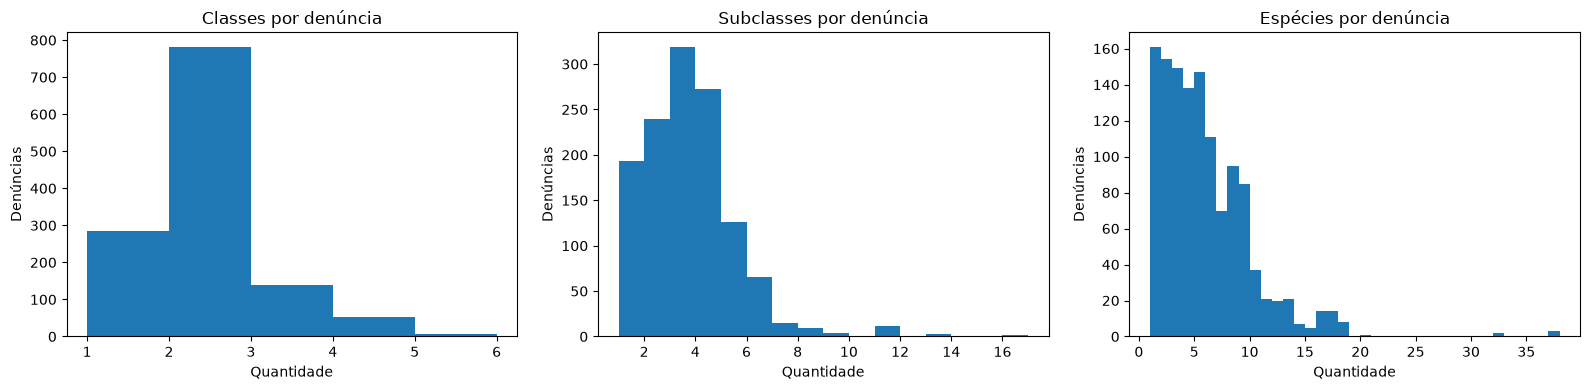

In [111]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, column, title in zip(
    axes,
    ["classes", "subclasses", "especies"],
    ["Classes por denúncia", "Subclasses por denúncia", "Espécies por denúncia"],
):
    ax.hist(resumo_denuncia[column], bins="auto")
    ax.set_title(title)
    ax.set_xlabel("Quantidade")
    ax.set_ylabel("Denúncias")
plt.tight_layout()
plt.show()

## 6. Construção das matrizes binárias


In [112]:
def build_binary_matrix(data: pd.DataFrame, id_column: str, category_column: str) -> pd.DataFrame:
    matrix = pd.crosstab(data[id_column], data[category_column])
    matrix = matrix.gt(0).astype("uint8")
    matrix.index.name = id_column
    return matrix

matriz_classe = build_binary_matrix(subconjunto, COL_DENUNCIA, COL_CLASSE)
matriz_subclasse = build_binary_matrix(subconjunto, COL_DENUNCIA, COL_SUBCLASSE)
matriz_especie = build_binary_matrix(subconjunto, COL_DENUNCIA, COL_ESPECIE)

matrizes_brutas = {
    "classe": matriz_classe,
    "subclasse": matriz_subclasse,
    "especie": matriz_especie,
}

pd.DataFrame({
    nome: {
        "denuncias": matriz.shape[0],
        "atributos": matriz.shape[1],
        "valores_1": int(matriz.to_numpy().sum()),
        "densidade": float(matriz.to_numpy().mean()),
        "esparsidade": 1 - float(matriz.to_numpy().mean()),
    }
    for nome, matriz in matrizes_brutas.items()
}).T

,denuncias,atributos,valores_1,densidade,esparsidade
classe,1263.0,8.0,2504.0,0.247823,0.752177
subclasse,1263.0,35.0,4176.0,0.094469,0.905531
especie,1263.0,80.0,6975.0,0.069032,0.930968


## 7. Suporte, prevalência e capacidade discriminatória

O suporte é calculado como a proporção de denúncias que possui cada categoria. Variáveis presentes em praticamente todas as denúncias ou em pouquíssimas denúncias tendem a ter baixa capacidade de separar agrupamentos.

Os valores padrão são:

- suporte mínimo proporcional: 1%;
- mínimo absoluto: 5 denúncias;
- suporte máximo: 99%.

Esses parâmetros devem ser analisados em conjunto, e não aplicados como regra universal.


In [113]:
def feature_diagnostics(matrix: pd.DataFrame) -> pd.DataFrame:
    count = matrix.sum(axis=0)
    support = matrix.mean(axis=0)
    variance = support * (1 - support)
    result = pd.DataFrame({
        "contagem_denuncias": count,
        "suporte": support,
        "variancia_bernoulli": variance,
    })
    return result.sort_values("suporte", ascending=False)

diagnosticos = {
    nome: feature_diagnostics(matriz)
    for nome, matriz in matrizes_brutas.items()
}

for nome, diagnostico in diagnosticos.items():
    print(f"{nome.upper()}")
    display(diagnostico.head(15))

CLASSE


,contagem_denuncias,suporte,variancia_bernoulli
violacao_classe,,,
LIBERDADE,1263,1.000000,0.000000
INTEGRIDADE,932,0.737926,0.193391
DIREITOS SOCIAIS,170,0.134600,0.116483
DIREITOS CIVIS E POLÍTICOS,49,0.038797,0.037291
VIOLÊNCIA INSTITUCIONAL,37,0.029295,0.028437
IGUALDADE,33,0.026128,0.025446
VIDA,19,0.015044,0.014817
SEGURANÇA,1,0.000792,0.000791


SUBCLASSE


,contagem_denuncias,suporte,variancia_bernoulli
violacao_subclasse,,,
DIREITOS INDIVIDUAIS,1263,1.000000,0.000000
PSÍQUICA,767,0.607284,0.238490
FÍSICA,658,0.520982,0.249560
NEGLIGÊNCIA,464,0.367379,0.232412
SEXUAL,414,0.327791,0.220344
PROTEÇÃO À INFÂNCIA,102,0.080760,0.074238
SEGURANÇA,76,0.060174,0.056553
LABORAL,75,0.059382,0.055856
PATRIMONIAL,63,0.049881,0.047393


ESPECIE


,contagem_denuncias,suporte,variancia_bernoulli
violacao_especie,,,
TRÁFICO DE PESSOAS,607,0.480602,0.249624
TRÁFICO DE CRIANÇAS,575,0.455265,0.247999
TORTURA PSÍQUICA,499,0.395091,0.238994
NEGLIGÊNCIA,464,0.367379,0.232412
EXPOSIÇÃO DE RISCO À SAÚDE,462,0.365796,0.231989
FÍSICA,378,0.299287,0.209714
AMEAÇA OU COAÇÃO,314,0.248614,0.186805
CONSTRANGIMENTO,310,0.245447,0.185203
MAUS TRATOS,273,0.216152,0.169430


In [114]:
def filter_features(
    matrix: pd.DataFrame,
    min_support: float = SUPORTE_MINIMO,
    max_support: float = SUPORTE_MAXIMO,
    min_count: int = MIN_OCORRENCIAS,
):
    diagnostics = feature_diagnostics(matrix)
    selected = diagnostics.index[
        diagnostics["contagem_denuncias"].ge(min_count)
        & diagnostics["suporte"].ge(min_support)
        & diagnostics["suporte"].le(max_support)
    ]
    return matrix.loc[:, selected].copy(), diagnostics

matrizes_filtradas = {}
relatorio_filtro = []

for nome, matriz in matrizes_brutas.items():
    filtrada, diagnostico = filter_features(matriz)
    matrizes_filtradas[nome] = filtrada
    relatorio_filtro.append({
        "nivel": nome,
        "atributos_antes": matriz.shape[1],
        "atributos_depois": filtrada.shape[1],
        "removidos": matriz.shape[1] - filtrada.shape[1],
        "densidade_depois": filtrada.to_numpy().mean() if filtrada.shape[1] else np.nan,
    })

display(pd.DataFrame(relatorio_filtro))

,nivel,atributos_antes,atributos_depois,removidos,densidade_depois
0,classe,8,6,2,0.163632
1,subclasse,35,17,18,0.132132
2,especie,80,47,33,0.114958


## 8. Tratamento do atributo usado na seleção

Como todas as denúncias foram selecionadas por conter tráfico, uma coluna equivalente a `TRÁFICO DE PESSOAS` pode ser constante. A coluna deve permanecer disponível para auditoria e interpretação, mas não deve entrar no clustering quando tiver variância zero ou prevalência extrema.


In [115]:
trafico_features = [
    column for column in matriz_especie.columns
    if pd.Series([column], dtype="string").str.contains(
        TERMO_TRAFICO, case=False, regex=True, na=False
    ).iloc[0]
]

print("Atributos de espécie associados ao termo de seleção:")
for column in trafico_features:
    print(
        f"- {column}: "
        f"{int(matriz_especie[column].sum())} denúncias "
        f"({matriz_especie[column].mean():.1%})"
    )

Atributos de espécie associados ao termo de seleção:
- TRÁFICO DE CRIANÇAS: 575 denúncias (45.5%)
- TRÁFICO DE MULHERES: 190 denúncias (15.0%)
- TRÁFICO DE PESSOAS: 607 denúncias (48.1%)


## 9. Comparação das representações


In [116]:
comparacao_representacoes = []
for nome, matriz in matrizes_filtradas.items():
    if matriz.shape[1] == 0:
        continue
    row_sums = matriz.sum(axis=1)
    duplicate_rate = matriz.duplicated().mean()
    comparacao_representacoes.append({
        "nivel": nome,
        "denuncias": matriz.shape[0],
        "atributos": matriz.shape[1],
        "media_atributos_ativos": row_sums.mean(),
        "mediana_atributos_ativos": row_sums.median(),
        "densidade": matriz.to_numpy().mean(),
        "esparsidade": 1 - matriz.to_numpy().mean(),
        "proporcao_perfis_duplicados": duplicate_rate,
    })

display(pd.DataFrame(comparacao_representacoes).set_index("nivel"))

,denuncias,atributos,media_atributos_ativos,mediana_atributos_ativos,densidade,esparsidade,proporcao_perfis_duplicados
nivel,,,,,,,
classe,1263,6,0.981789,1.0,0.163632,0.836368,0.981789
subclasse,1263,17,2.246239,2.0,0.132132,0.867868,0.907363
especie,1263,47,5.403009,5.0,0.114958,0.885042,0.586698


## 10. Distância de Jaccard e agrupamento hierárquico

A distância de Jaccard compara conjuntos de violações presentes em cada denúncia e ignora ausências compartilhadas. Isso é apropriado para matrizes binárias esparsas.

Para evitar consumo excessivo de memória, a matriz completa de distâncias só deve ser criada quando o número de denúncias for administrável. O limite padrão abaixo é 5.000 denúncias.


In [117]:
NIVEL_PRINCIPAL = "subclasse"
X_binary = matrizes_filtradas[NIVEL_PRINCIPAL].copy()
assert X_binary.shape[1] >= 2, "A representação selecionada possui poucos atributos."

MAX_JACCARD_FULL = 5000
if len(X_binary) <= MAX_JACCARD_FULL:
    distancia_jaccard = pairwise_distances(X_binary.to_numpy(dtype=bool), metric="jaccard")
    print("Matriz Jaccard criada:", distancia_jaccard.shape)
else:
    distancia_jaccard = None
    print(
        f"Matriz Jaccard completa não criada: {len(X_binary):,} denúncias excedem "
        f"o limite de {MAX_JACCARD_FULL:,}. Use amostragem ou HDBSCAN com representação reduzida."
    )

Matriz Jaccard criada: (1263, 1263)


In [118]:
def evaluate_precomputed_clustering(distance_matrix, labels):
    valid = labels >= 0
    n_clusters = len(set(labels[valid]))
    if valid.sum() < 3 or n_clusters < 2:
        return np.nan
    return silhouette_score(
        distance_matrix[np.ix_(valid, valid)],
        labels[valid],
        metric="precomputed",
    )

resultados_aglomerativo = []
modelos_aglomerativos = {}

if distancia_jaccard is not None:
    max_k = min(10, len(X_binary) - 1)
    for k in range(2, max_k + 1):
        model = AgglomerativeClustering(
            n_clusters=k,
            metric="precomputed",
            linkage="average",
        )
        labels = model.fit_predict(distancia_jaccard)
        score = evaluate_precomputed_clustering(distancia_jaccard, labels)
        resultados_aglomerativo.append({"k": k, "silhouette_jaccard": score})
        modelos_aglomerativos[k] = (model, labels)

    display(pd.DataFrame(resultados_aglomerativo).sort_values("silhouette_jaccard", ascending=False))

,k,silhouette_jaccard
0,2,0.441431
2,4,0.440869
1,3,0.440745
3,5,0.439610
4,6,0.424831
5,7,0.395604
6,8,0.394532
7,9,0.336105
8,10,0.307912


## 11. Baseline: Truncated SVD + K-Means

K-Means não é o modelo principal para dados binários esparsos, mas funciona como baseline após redução com Truncated SVD. A comparação ajuda a verificar se a estrutura encontrada depende exclusivamente do algoritmo principal.


In [119]:
n_components = min(20, X_binary.shape[1] - 1, X_binary.shape[0] - 1)
assert n_components >= 2, "Dados insuficientes para Truncated SVD."

svd = TruncatedSVD(n_components=n_components, random_state=RANDOM_STATE)
X_svd = svd.fit_transform(sparse.csr_matrix(X_binary))
X_svd_norm = normalize(X_svd)

print("Componentes:", n_components)
print("Variância explicada acumulada:", svd.explained_variance_ratio_.sum())

Componentes: 16
Variância explicada acumulada: 0.9981164142616712


In [120]:
resultados_kmeans = []
modelos_kmeans = {}
max_k = min(10, len(X_binary) - 1)

for k in range(2, max_k + 1):
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = model.fit_predict(X_svd_norm)
    resultados_kmeans.append({
        "k": k,
        "silhouette_cosine": silhouette_score(X_svd_norm, labels, metric="cosine"),
        "davies_bouldin": davies_bouldin_score(X_svd_norm, labels),
        "inercia": model.inertia_,
    })
    modelos_kmeans[k] = (model, labels)

resultados_kmeans_df = pd.DataFrame(resultados_kmeans)
display(resultados_kmeans_df.sort_values("silhouette_cosine", ascending=False))

,k,silhouette_cosine,davies_bouldin,inercia
8,10,0.435396,1.011173,182.091368
7,9,0.427623,0.980029,198.009167
6,8,0.397807,1.075066,222.058343
5,7,0.386309,1.172984,238.068642
4,6,0.375149,1.165449,263.424780
0,2,0.352611,1.708684,499.259708
3,5,0.352328,1.183619,295.328437
1,3,0.342904,1.307654,408.152258
2,4,0.332934,1.369500,338.934633


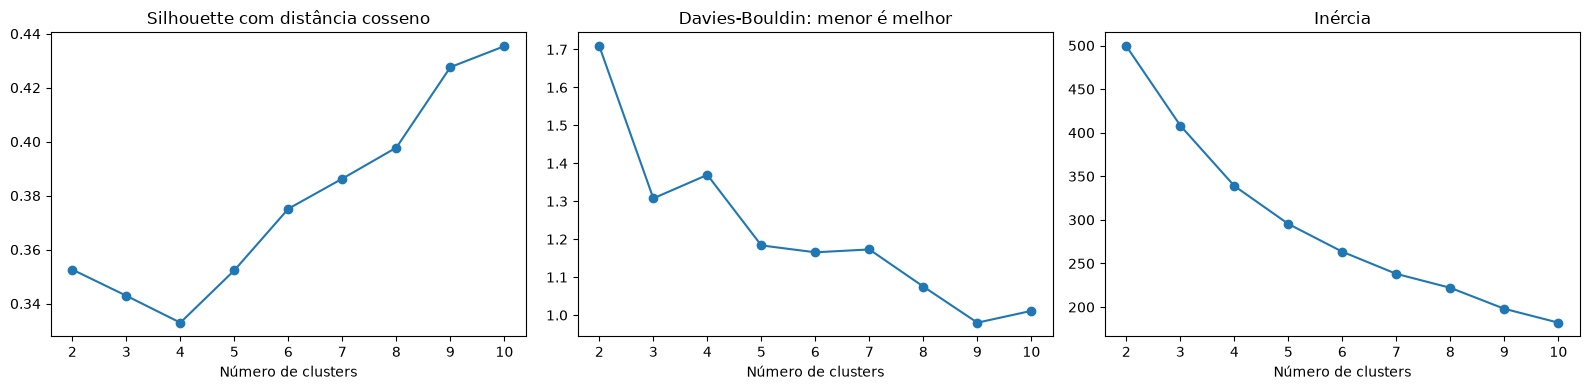

In [121]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(resultados_kmeans_df["k"], resultados_kmeans_df["silhouette_cosine"], marker="o")
axes[0].set_title("Silhouette com distância cosseno")
axes[1].plot(resultados_kmeans_df["k"], resultados_kmeans_df["davies_bouldin"], marker="o")
axes[1].set_title("Davies-Bouldin: menor é melhor")
axes[2].plot(resultados_kmeans_df["k"], resultados_kmeans_df["inercia"], marker="o")
axes[2].set_title("Inércia")
for ax in axes:
    ax.set_xlabel("Número de clusters")
plt.tight_layout()
plt.show()

## 12. Modelo principal opcional: UMAP + HDBSCAN

O bloco é executado somente se `umap-learn` e `hdbscan` estiverem instalados. Para matrizes binárias, UMAP usa distância de Jaccard. O HDBSCAN identifica agrupamentos de densidade variável e pode marcar denúncias como ruído (`cluster = -1`).

Instalação no ambiente do notebook, se necessária:

`%pip install umap-learn hdbscan`


In [122]:
HAS_UMAP = importlib.util.find_spec("umap") is not None
HAS_HDBSCAN = importlib.util.find_spec("hdbscan") is not None

if HAS_UMAP and HAS_HDBSCAN:
    import umap.umap_ as umap
    import hdbscan

    n_neighbors = min(30, max(2, len(X_binary) - 1))
    reducer = umap.UMAP(
        n_components=10,
        n_neighbors=n_neighbors,
        min_dist=0.0,
        metric="jaccard",
        random_state=RANDOM_STATE,
    )
    X_umap = reducer.fit_transform(X_binary.astype(bool))

    min_cluster_size = max(10, int(np.ceil(0.02 * len(X_binary))))
    min_samples = max(5, min_cluster_size // 2)

    modelo_hdbscan = hdbscan.HDBSCAN(
        min_cluster_size=min_cluster_size,
        min_samples=min_samples,
        metric="euclidean",
        cluster_selection_method="eom",
        prediction_data=True,
    )
    labels_hdbscan = modelo_hdbscan.fit_predict(X_umap)

    print("min_cluster_size:", min_cluster_size)
    print("min_samples:", min_samples)
    print("clusters:", len(set(labels_hdbscan)) - (1 if -1 in labels_hdbscan else 0))
    print("ruído:", np.mean(labels_hdbscan == -1))
else:
    X_umap = None
    labels_hdbscan = None
    print("UMAP + HDBSCAN não executado. Instale `umap-learn` e `hdbscan`.")

UMAP + HDBSCAN não executado. Instale `umap-learn` e `hdbscan`.


In [123]:
if X_umap is not None:
    valid = labels_hdbscan >= 0
    n_clusters = len(set(labels_hdbscan[valid]))
    silhouette_hdbscan = (
        silhouette_score(X_umap[valid], labels_hdbscan[valid])
        if valid.sum() >= 3 and n_clusters >= 2
        else np.nan
    )
    print("Silhouette sem ruído:", silhouette_hdbscan)

    # UMAP bidimensional usado somente para visualização.
    reducer_2d = umap.UMAP(
        n_components=2,
        n_neighbors=min(30, max(2, len(X_binary) - 1)),
        min_dist=0.1,
        metric="jaccard",
        random_state=RANDOM_STATE,
    )
    X_umap_2d = reducer_2d.fit_transform(X_binary.astype(bool))

    fig, ax = plt.subplots(figsize=(9, 7))
    scatter = ax.scatter(
        X_umap_2d[:, 0], X_umap_2d[:, 1],
        c=labels_hdbscan, s=18, alpha=0.75, cmap="tab20"
    )
    ax.set_title("UMAP das denúncias por cluster HDBSCAN")
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")
    plt.tight_layout()
    plt.show()

## 13. Escolha explícita do modelo final

A escolha não deve ser feita apenas pelo maior silhouette. Considere também:

- proporção de ruído;
- tamanho mínimo dos clusters;
- estabilidade sob reamostragem;
- coerência das violações predominantes;
- utilidade substantiva para interpretar perfis de tráfico.

A célula escolhe automaticamente HDBSCAN quando disponível e com pelo menos dois clusters; caso contrário, usa o melhor K-Means por silhouette cosseno. A decisão pode ser substituída após a avaliação.


In [124]:
if labels_hdbscan is not None and len(set(labels_hdbscan[labels_hdbscan >= 0])) >= 2:
    MODELO_FINAL = "umap_hdbscan"
    labels_final = labels_hdbscan
else:
    melhor_k = int(
        resultados_kmeans_df.sort_values(
            ["silhouette_cosine", "davies_bouldin"],
            ascending=[False, True],
        ).iloc[0]["k"]
    )
    MODELO_FINAL = f"svd_kmeans_k{melhor_k}"
    labels_final = modelos_kmeans[melhor_k][1]

clusters = pd.Series(labels_final, index=X_binary.index, name="cluster")
print("Modelo final provisório:", MODELO_FINAL)
display(clusters.value_counts(dropna=False).sort_index().to_frame("denuncias"))

Modelo final provisório: svd_kmeans_k10


,denuncias
cluster,
0,199
1,147
2,83
3,197
4,103
5,227
6,82
7,70
8,64


## 14. Estabilidade por reamostragem


In [125]:
def bootstrap_kmeans_stability(X, k, iterations=30, sample_fraction=0.80, random_state=42):
    rng = np.random.default_rng(random_state)
    base = KMeans(n_clusters=k, random_state=random_state, n_init=20).fit_predict(X)
    scores = []

    n_sample = max(k + 1, int(np.floor(sample_fraction * len(X))))
    for i in range(iterations):
        idx = np.sort(rng.choice(len(X), size=n_sample, replace=False))
        labels = KMeans(
            n_clusters=k,
            random_state=random_state + i + 1,
            n_init=20,
        ).fit_predict(X[idx])
        scores.append(adjusted_rand_score(base[idx], labels))

    return pd.Series(scores, name="adjusted_rand_index")

if MODELO_FINAL.startswith("svd_kmeans"):
    estabilidade = bootstrap_kmeans_stability(X_svd_norm, melhor_k)
    display(estabilidade.describe().to_frame("resultado"))
else:
    print(
        "Para HDBSCAN, recomenda-se repetir UMAP + HDBSCAN em subamostras e comparar "
        "pares de denúncias com Adjusted Rand Index. A implementação depende da proporção "
        "de ruído e será ajustada após observar o modelo final."
    )

,resultado
count,30.000000
mean,0.838186
std,0.060575
min,0.699347
25%,0.821074
50%,0.828772
75%,0.877333
max,1.000000


## 15. Perfil dos clusters pelas subclasses

A prevalência é a proporção de denúncias do cluster que contém a categoria. O _lift_ compara essa prevalência com a prevalência global. Valores maiores que 1 indicam sobrerrepresentação.


In [126]:
def cluster_feature_profile(matrix: pd.DataFrame, labels: pd.Series, top_n=12):
    aligned = matrix.loc[labels.index]
    global_prevalence = aligned.mean(axis=0)
    rows = []

    for cluster_id in sorted(labels.unique()):
        member_ids = labels.index[labels.eq(cluster_id)]
        prevalence = aligned.loc[member_ids].mean(axis=0)
        lift = prevalence.div(global_prevalence.replace(0, np.nan))
        table = pd.DataFrame({
            "cluster": cluster_id,
            "atributo": prevalence.index,
            "prevalencia_cluster": prevalence.values,
            "prevalencia_global": global_prevalence.values,
            "lift": lift.values,
            "denuncias_cluster": len(member_ids),
        })
        table = table.sort_values(
            ["lift", "prevalencia_cluster"], ascending=False
        ).head(top_n)
        rows.append(table)

    return pd.concat(rows, ignore_index=True)

perfil_subclasse = cluster_feature_profile(
    matriz_subclasse.loc[clusters.index], clusters, top_n=12
)
display(perfil_subclasse)

,cluster,atributo,prevalencia_cluster,prevalencia_global,lift,denuncias_cluster
0,0,SUICÍDIO,0.015075,0.002375,6.346734,199
1,0,EDUCAÇÃO,0.045226,0.011085,4.080043,199
2,0,MORADIA,0.005025,0.001584,3.173367,199
3,0,EXPRESSÃO,0.015075,0.004751,3.173367,199
4,0,SEXUAL,1.000000,0.327791,3.050725,199
...,...,...,...,...,...,...
115,9,LABORAL,0.010989,0.059382,0.185055,91
116,9,ABORTO,0.000000,0.001584,0.000000,91
117,9,ACESSO À INFORMAÇÃO,0.000000,0.007918,0.000000,91
118,9,ALIMENTAÇÃO,0.000000,0.006334,0.000000,91


## 16. Interpretação dos clusters pelas espécies


In [127]:
perfil_especie = cluster_feature_profile(
    matriz_especie.loc[clusters.index], clusters, top_n=15
)
display(perfil_especie)

,cluster,atributo,prevalencia_cluster,prevalencia_global,lift,denuncias_cluster
0,0,ESTUPRO CORRETIVO,0.015075,0.002375,6.346734,199
1,0,PATRIMÔNIO IMATERIAL,0.015075,0.002375,6.346734,199
2,0,SUICÍDIO,0.015075,0.002375,6.346734,199
3,0,VIOLÊNCIA SEXUAL MEDIANTE FRAUDE,0.050251,0.010293,4.882103,199
4,0,ASSÉDIO MORAL,0.120603,0.026920,4.480047,199
...,...,...,...,...,...,...
145,9,CALÚNIA,0.010989,0.015835,0.693956,91
146,9,EM RAZÃO DE SER POLICIAL/MILITAR/DEMAIS AGENTE DE SEGURANÇA PÚBLICA,0.010989,0.016627,0.660911,91
147,9,CONDIÇÃO ANÁLOGA À DE ESCRAVO,0.043956,0.083135,0.528728,91
148,9,INJÚRIA,0.021978,0.044339,0.495683,91


In [128]:
for cluster_id in sorted(clusters.unique()):
    print(f"CLUSTER {cluster_id}")
    display(
        perfil_especie.loc[perfil_especie["cluster"].eq(cluster_id), [
            "atributo", "prevalencia_cluster", "prevalencia_global", "lift"
        ]]
    )

CLUSTER 0


,atributo,prevalencia_cluster,prevalencia_global,lift
0,ESTUPRO CORRETIVO,0.015075,0.002375,6.346734
1,PATRIMÔNIO IMATERIAL,0.015075,0.002375,6.346734
2,SUICÍDIO,0.015075,0.002375,6.346734
3,VIOLÊNCIA SEXUAL MEDIANTE FRAUDE,0.050251,0.010293,4.882103
4,ASSÉDIO MORAL,0.120603,0.026920,4.480047
5,IMPORTUNAÇÃO SEXUAL,0.100503,0.022961,4.377058
6,EXPOSIÇÃO (EROTIZAÇÃO),0.336683,0.079177,4.252312
7,COLETIVO,0.020101,0.004751,4.231156
8,PARA FINS DE EXPLORAÇÃO DO TRABALHO,0.020101,0.004751,4.231156
9,EDUCAÇÃO,0.045226,0.011085,4.080043


CLUSTER 1


,atributo,prevalencia_cluster,prevalencia_global,lift
15,INCITAÇÃO AO SUICÍDIO,0.013605,0.001584,8.591837
16,IMPEDIMENTO DE TRABALHO/OFÍCIO/PROFISSÃO,0.006803,0.000792,8.591837
17,LAZER,0.006803,0.000792,8.591837
18,RACISMO,0.129252,0.024545,5.265964
19,SITUAÇÃO DE RUA OU ABANDONO MATERIAL,0.027211,0.006334,4.295918
20,MORADIA,0.006803,0.001584,4.295918
21,NACIONALIDADE,0.006803,0.001584,4.295918
22,RETENÇÃO DE DOCUMENTOS,0.108844,0.027712,3.927697
23,TORTURA FÍSICA,0.258503,0.071259,3.627664
24,INJÚRIA,0.156463,0.044339,3.528790


CLUSTER 2


,atributo,prevalencia_cluster,prevalencia_global,lift
30,ESTUPRO DE VULNERÁVEL,0.325301,0.102138,3.184926
31,TRABALHO INFANTIL,0.072289,0.022961,3.148317
32,EXPOSIÇÃO (EROTIZAÇÃO),0.228916,0.079177,2.891205
33,FÍSICA,0.855422,0.299287,2.858195
34,PSÍQUICA,0.204819,0.087094,2.351698
35,AMEAÇA OU COAÇÃO,0.566265,0.248614,2.277684
36,TRÁFICO DE MULHERES,0.277108,0.150435,1.842042
37,EXPOSIÇÃO,0.349398,0.212193,1.646601
38,LIBERDADE DE IR VIR PERMANECER,0.108434,0.066508,1.630379
39,CÁRCERE PRIVADO,0.132530,0.102138,1.297562


... (10 outputs left out)

CLUSTER 8


,atributo,prevalencia_cluster,prevalencia_global,lift
120,INJÚRIA RACIAL E ÉTNICA,0.031250,0.001584,19.734375
121,DISCRIMINAÇÃO,0.031250,0.003167,9.867188
122,NÃO CRENÇA,0.015625,0.002375,6.578125
123,FALTA DE ACESSIBILIDADE,0.015625,0.004751,3.289062
124,LIBERDADE DE CONSCIÊNCIA E DE PENSAMENTO,0.015625,0.004751,3.289062
125,RACISMO,0.078125,0.024545,3.182964
126,LIBERDADE DE IR VIR PERMANECER,0.156250,0.066508,2.349330
127,ALIENAÇÃO PARENTAL,0.031250,0.014252,2.192708
128,ACESSO À INFORMAÇÃO,0.015625,0.007918,1.973438
129,EXPOSIÇÃO,0.406250,0.212193,1.914529


CLUSTER 9


,atributo,prevalencia_cluster,prevalencia_global,lift
135,NEGLIGÊNCIA,1.000000,0.367379,2.721983
136,INSUBSISTÊNCIA AFETIVA,0.197802,0.108472,1.823534
137,ALIENAÇÃO PARENTAL,0.021978,0.014252,1.542125
138,CONSTRANGIMENTO,0.373626,0.245447,1.522226
139,EXPOSIÇÃO,0.318681,0.212193,1.501845
140,TRÁFICO DE CRIANÇAS,0.615385,0.455265,1.351706
141,TORTURA PSÍQUICA,0.395604,0.395091,1.001299
142,EXPOSIÇÃO (EROTIZAÇÃO),0.076923,0.079177,0.971538
143,AMEAÇA OU COAÇÃO,0.219780,0.248614,0.884020
144,TRÁFICO DE PESSOAS,0.362637,0.480602,0.754549


## 17. Caracterização externa dos clusters

As variáveis externas não entram obrigatoriamente no clustering. Elas são agregadas por denúncia e usadas para compreender os perfis encontrados. Ajuste `CANDIDATAS_CATEGORICAS` aos nomes existentes no conjunto.


In [146]:
CANDIDATAS_CATEGORICAS = [
    "mes_cadastro", "uf", "genero_da_vitima", "faixa_etaria_da_vitima_recodificada", "canal_atendimento",
    "relacao_vitima_suspeito_agrupada", "violacao_abrangencia",
]
CATEGORICAS_DISPONIVEIS = [
    column for column in CANDIDATAS_CATEGORICAS if column in subconjunto.columns
]
print("Variáveis externas disponíveis:", CATEGORICAS_DISPONIVEIS)

Variáveis externas disponíveis: ['mes_cadastro', 'uf', 'genero_da_vitima', 'faixa_etaria_da_vitima_recodificada', 'relacao_vitima_suspeito_agrupada', 'violacao_abrangencia']


In [147]:
def aggregate_mode(series: pd.Series):
    mode = series.dropna().mode()
    return mode.iloc[0] if len(mode) else pd.NA

if CATEGORICAS_DISPONIVEIS:
    metadados_denuncia = (
        subconjunto.groupby(COL_DENUNCIA)[CATEGORICAS_DISPONIVEIS]
        .agg(aggregate_mode)
        .join(clusters)
    )

    for column in CATEGORICAS_DISPONIVEIS:
        print(f"{column}")
        table = pd.crosstab(
            metadados_denuncia["cluster"],
            metadados_denuncia[column],
            normalize="index",
        )
        display(table)
else:
    metadados_denuncia = clusters.to_frame()
    print("Nenhuma variável externa candidata foi encontrada.")

mes_cadastro


mes_cadastro,1,2,3,4,5,6,7,8,9,10,11,12
cluster,,,,,,,,,,,,
0,0.025126,0.115578,0.175879,0.070352,0.015075,0.090452,0.155779,0.055276,0.065327,0.060302,0.030151,0.140704
1,0.047619,0.210884,0.068027,0.068027,0.027211,0.081633,0.170068,0.122449,0.068027,0.047619,0.040816,0.047619
2,0.036145,0.024096,0.108434,0.060241,0.120482,0.000000,0.012048,0.156627,0.084337,0.204819,0.036145,0.156627
3,0.030457,0.055838,0.086294,0.060914,0.055838,0.020305,0.228426,0.065990,0.126904,0.116751,0.086294,0.065990
4,0.038835,0.019417,0.485437,0.048544,0.048544,0.038835,0.019417,0.029126,0.038835,0.135922,0.029126,0.067961
5,0.061674,0.202643,0.092511,0.026432,0.044053,0.057269,0.026432,0.061674,0.114537,0.132159,0.114537,0.066079
6,0.060976,0.268293,0.109756,0.073171,0.060976,0.012195,0.060976,0.170732,0.036585,0.060976,0.012195,0.073171
7,0.100000,0.085714,0.142857,0.071429,0.014286,0.042857,0.142857,0.028571,0.100000,0.142857,0.071429,0.057143
8,0.093750,0.125000,0.031250,0.109375,0.031250,0.093750,0.000000,0.109375,0.140625,0.156250,0.062500,0.046875


uf


uf,AC,AL,AM,AP,ATENDIMENTO INTERROMPIDO,BA,CE,DF,ES,GO,MA,MG,MS,MT,NÃO INFORMADO,PA,PB,PE,PI,PR,RJ,RN,RO,RR,RS,SC,SE,SP,TO
cluster,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,0.049724,0.000000,0.060773,0.005525,0.000000,0.055249,0.000000,0.000000,0.022099,0.049724,0.016575,0.027624,0.016575,0.016575,0.088398,0.038674,0.011050,0.049724,0.000000,0.044199,0.044199,0.038674,0.000000,0.038674,0.027624,0.027624,0.033149,0.237569,0.00000
1,0.000000,0.006944,0.013889,0.000000,0.013889,0.013889,0.006944,0.027778,0.027778,0.006944,0.006944,0.250000,0.006944,0.006944,0.083333,0.000000,0.000000,0.006944,0.000000,0.048611,0.104167,0.020833,0.020833,0.000000,0.006944,0.006944,0.000000,0.312500,0.00000
2,0.000000,0.014085,0.000000,0.000000,0.000000,0.028169,0.000000,0.000000,0.000000,0.056338,0.000000,0.098592,0.000000,0.000000,0.056338,0.014085,0.028169,0.028169,0.000000,0.028169,0.281690,0.000000,0.014085,0.014085,0.126761,0.070423,0.000000,0.140845,0.00000
3,0.000000,0.000000,0.011050,0.000000,0.000000,0.027624,0.138122,0.011050,0.038674,0.022099,0.005525,0.132597,0.016575,0.005525,0.082873,0.000000,0.005525,0.011050,0.000000,0.049724,0.099448,0.016575,0.016575,0.000000,0.077348,0.000000,0.000000,0.220994,0.01105
4,0.000000,0.000000,0.009709,0.000000,0.000000,0.038835,0.087379,0.009709,0.000000,0.009709,0.000000,0.019417,0.019417,0.000000,0.106796,0.009709,0.000000,0.097087,0.000000,0.106796,0.029126,0.000000,0.000000,0.000000,0.359223,0.000000,0.000000,0.097087,0.00000
5,0.000000,0.000000,0.014085,0.000000,0.000000,0.028169,0.018779,0.037559,0.018779,0.093897,0.000000,0.173709,0.004695,0.004695,0.098592,0.014085,0.004695,0.018779,0.000000,0.023474,0.042254,0.056338,0.000000,0.009390,0.154930,0.018779,0.014085,0.150235,0.00000
6,0.024691,0.000000,0.074074,0.000000,0.000000,0.024691,0.024691,0.012346,0.000000,0.000000,0.000000,0.074074,0.000000,0.000000,0.111111,0.000000,0.000000,0.061728,0.012346,0.049383,0.123457,0.000000,0.000000,0.000000,0.135802,0.024691,0.000000,0.246914,0.00000
7,0.000000,0.000000,0.000000,0.000000,0.000000,0.046154,0.000000,0.000000,0.015385,0.076923,0.015385,0.076923,0.000000,0.015385,0.169231,0.000000,0.000000,0.123077,0.000000,0.092308,0.061538,0.046154,0.000000,0.000000,0.030769,0.000000,0.000000,0.230769,0.00000
8,0.000000,0.000000,0.016393,0.000000,0.000000,0.032787,0.065574,0.065574,0.032787,0.065574,0.000000,0.114754,0.000000,0.000000,0.098361,0.000000,0.000000,0.016393,0.000000,0.016393,0.180328,0.016393,0.000000,0.016393,0.032787,0.081967,0.000000,0.147541,0.00000


genero_da_vitima


genero_da_vitima,FEMININO,INTERSEXO,MASCULINO,NÃO INFORMADO,NÃO SE APLICA
cluster,,,,,
0,0.732026,0.006536,0.163399,0.052288,0.045752
1,0.440367,0.000000,0.477064,0.073394,0.009174
2,0.690141,0.000000,0.154930,0.042254,0.112676
3,0.576687,0.000000,0.331288,0.061350,0.030675
4,0.556818,0.000000,0.375000,0.011364,0.056818
5,0.508108,0.043243,0.345946,0.081081,0.021622
6,0.724638,0.000000,0.159420,0.028986,0.086957
7,0.471698,0.000000,0.415094,0.018868,0.094340
8,0.500000,0.000000,0.375000,0.062500,0.062500


... (2 outputs left out)

relacao_vitima_suspeito_agrupada


relacao_vitima_suspeito_agrupada,AMIGO/CONHECIDO,DESCONHECIDO/NÃO INFORMADO,FAMILIAR,OUTROS,PARCEIRO ÍNTIMO,RELAÇÃO INSTITUCIONAL,RELAÇÃO PROFISSIONAL
cluster,,,,,,,
0,0.030151,0.271357,0.145729,0.482412,0.000000,0.030151,0.040201
1,0.027778,0.222222,0.194444,0.479167,0.020833,0.020833,0.034722
2,0.012048,0.433735,0.156627,0.349398,0.012048,0.000000,0.036145
3,0.050761,0.152284,0.274112,0.426396,0.005076,0.000000,0.091371
4,0.000000,0.669903,0.000000,0.262136,0.019417,0.009709,0.038835
5,0.061674,0.299559,0.149780,0.453744,0.008811,0.000000,0.026432
6,0.012346,0.185185,0.407407,0.345679,0.000000,0.000000,0.049383
7,0.000000,0.328571,0.285714,0.357143,0.000000,0.000000,0.028571
8,0.015625,0.375000,0.171875,0.281250,0.015625,0.015625,0.125000


violacao_abrangencia


violacao_abrangencia,INTERNACIONAL,NACIONAL
cluster,,
0,0.442211,0.557789
1,0.666667,0.333333
2,0.481928,0.518072
3,0.380711,0.619289
4,0.524272,0.475728
5,0.590308,0.409692
6,0.207317,0.792683
7,0.385714,0.614286
8,0.406250,0.593750


In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))

imagem = ax.imshow(table.to_numpy(), cmap="YlOrRd", vmin=0, vmax=1, aspect="auto")

ax.set_xticks(range(len(table.columns)), table.columns, rotation=30, ha="right")
ax.set_yticks(range(len(table.index)), table.index)
ax.set_xlabel("Abrangência")
ax.set_ylabel("Cluster")
ax.set_title("Abrangência das denúncias por cluster")

for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        ax.text(j, i, f"{table.iloc[i, j]:.1%}", ha="center", va="center")

fig.colorbar(imagem, ax=ax, label="Proporção")
plt.tight_layout()
plt.show()

## 18. Tabela analítica final e exportação

São exportados:

- cluster por denúncia;
- perfis de subclasse;
- perfis de espécie;
- relatório dos filtros de atributos;
- matrizes binárias filtradas, se desejado.


In [144]:
resultado_denuncias = (
    resumo_denuncia
    .join(clusters, how="inner")
    .reset_index()
)
resultado_denuncias["modelo"] = MODELO_FINAL

relatorio_filtros = pd.DataFrame(relatorio_filtro)

display(resultado_denuncias.head())

,hash,ocorrencias,classes,subclasses,especies,cluster,modelo
0,002F819E35D44A499A7A94986A57219BF5D730B561452B41545964AF67F343D8,5,2,3,5,1,svd_kmeans_k10
1,00319EA24D89AC6035B7BE828079576473D1BB2F233C7845740097BEC2F9CE57,1,1,1,1,5,svd_kmeans_k10
2,005929E4587AF2DA96A76E5590A542467A1E397D0FAAEEDE13ABF1ADC110883B,7,2,4,5,0,svd_kmeans_k10
3,0062DF297FE1A0C845F3AC8DCFB177903DA85F777C1AADD3C5DEAA6E59725C0A,2,2,2,2,7,svd_kmeans_k10
4,007E8ED8E6552B24B9A9B3A33E86D98FB1F9F9BE049F8CB7926E965FFF435B57,10,2,4,4,0,svd_kmeans_k10


In [132]:
# Descomente após validar a solução final.
# resultado_denuncias.to_csv("clusters_denuncias_trafico.csv", index=False, encoding="utf-8-sig")
# perfil_subclasse.to_csv("perfil_clusters_subclasse.csv", index=False, encoding="utf-8-sig")
# perfil_especie.to_csv("perfil_clusters_especie.csv", index=False, encoding="utf-8-sig")
# relatorio_filtros.to_csv("relatorio_filtro_atributos.csv", index=False, encoding="utf-8-sig")
# matrizes_filtradas["subclasse"].to_parquet("matriz_denuncia_subclasse.parquet")

print("Resultado disponível em `resultado_denuncias`.")

Resultado disponível em `resultado_denuncias`.


## 19. Checklist de avaliação metodológica

Antes de interpretar os agrupamentos no artigo, registre:

- [ ] número de denúncias selecionadas;
- [ ] número de violações concomitantes preservadas;
- [ ] variáveis removidas por suporte baixo ou prevalência extrema;
- [ ] densidade e esparsidade de cada representação;
- [ ] métrica de distância utilizada;
- [ ] hiperparâmetros dos algoritmos;
- [ ] quantidade e tamanho dos clusters;
- [ ] proporção de ruído, quando aplicável;
- [ ] silhouette e Davies-Bouldin, quando aplicáveis;
- [ ] estabilidade por reamostragem;
- [ ] prevalência e lift das subclasses e espécies em cada cluster;
- [ ] coerência substantiva com a taxonomia do Disque 100;
- [ ] limitações decorrentes de subnotificação, preenchimento administrativo e categorias raras.


## 20. Texto-base para a metodologia

As denúncias relacionadas ao tráfico de pessoas foram identificadas pela presença de pelo menos uma espécie de violação cujo rótulo continha o termo “tráfico”. Após a identificação das chaves das denúncias, todas as violações registradas nas mesmas denúncias foram preservadas, com o objetivo de representar a natureza multidimensional do fenômeno. A unidade de análise foi a denúncia, e as ocorrências foram agregadas em matrizes binárias de presença ou ausência nos níveis de classe, subclasse e espécie da taxonomia.

A seleção dos atributos considerou o número absoluto de denúncias, o suporte proporcional, a prevalência extrema e a variância das variáveis binárias. A representação principal foi definida após a comparação da dimensionalidade, esparsidade e capacidade discriminatória dos níveis taxonômicos. Foram comparados agrupamento hierárquico com distância de Jaccard, K-Means após redução por Truncated SVD e, quando disponíveis, UMAP e HDBSCAN. A avaliação considerou separação interna, proporção de ruído, estabilidade por reamostragem e interpretabilidade substantiva. Os agrupamentos foram caracterizados pelas prevalências e pelos valores de lift das subclasses e espécies de violação, além de variáveis externas agregadas no nível da denúncia.
